# Week 2.2: Context Window Management

## Key Insight
> **Why can't you just paste a 500-page book into the prompt?**

## Learning Objectives
By the end of this notebook, you will:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.2: Context Window Management - Ready to start!')
print('\nTopics covered:')
print('  - Understanding token limits and context windows')
print('  - Token counting and estimation techniques')
print('  - Context compression strategies')
print('  - Conversation history management')
print('  - Sliding window approaches')


✅ Week 2.2: Context Window Management - Ready to start!

Topics covered:
  - Understanding token limits and context windows
  - Token counting and estimation techniques
  - Context compression strategies
  - Conversation history management
  - Sliding window approaches


---
## Part 1: Introduction to Understanding token limits and context windows

Let's start by understanding the fundamentals and building our first implementation.

In [3]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Understanding token limits and context windows.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [8]:
# YOUR CODE HERE
class ContextWindowMonitor:
    """
    Exercise 1: Basic Context Window Tracker.
    Monitors token limits, estimates token counts, and warns when limits are exceeded.
    """
    def __init__(self, max_tokens: int = 4096):
        if not isinstance(max_tokens, int) or max_tokens <= 0:
            raise ValueError("max_tokens must be a positive integer.")
        self.max_tokens = max_tokens
        self.history = []

    def estimate_tokens(self, text: str) -> int:
        """
        Estimates token count using the standard ~4 chars or 0.75 words per token heuristic.
        """
        if not isinstance(text, str):
            raise TypeError("Input text must be a string.")

        cleaned = text.strip()
        if not cleaned:
            return 0

        # Common LLM heuristic: ~4 characters per token
        char_estimate = len(cleaned) / 4.0
        # Word heuristic: ~1.33 tokens per word (0.75 words per token)
        word_estimate = len(cleaned.split()) * 1.33

        # Take the conservative ceiling average
        return max(1, int(round((char_estimate + word_estimate) / 2)))

    def process(self, input_text: str) -> Dict[str, Any]:
        """
        Process the incoming text, calculate usage, and verify context window safety.
        """
        # Edge case: empty or invalid data
        if not isinstance(input_text, str):
            raise TypeError(f"Expected string input, got {type(input_text).__name__}")

        token_count = self.estimate_tokens(input_text)
        available_space = self.max_tokens - token_count
        usage_ratio = round(token_count / self.max_tokens, 4)
        is_safe = token_count <= self.max_tokens

        result = {
            'text_length': len(input_text),
            'estimated_tokens': token_count,
            'max_tokens': self.max_tokens,
            'remaining_tokens': max(0, available_space),
            'usage_ratio': usage_ratio,
            'is_within_limit': is_safe,
            'status': 'OK' if is_safe else 'CONTEXT_WINDOW_EXCEEDED'
        }

        self.history.append(result)
        return result

monitor = ContextWindowMonitor(max_tokens=100)

test_cases = [
    ("Short prompt", "Hello! Who won the marathon yesterday?"),
    ("Moderate prompt", "A digital twin is a virtual representation of a physical object or system, capturing personal logs and habits."),
    ("Edge case (Empty)", "   "),
    ("Oversized prompt", "Lorem ipsum " * 80)
]

print("=" * 65)
print("TESTING CONTEXT WINDOW MONITOR")
print("=" * 65)

for label, test_text in test_cases:
    res = monitor.process(test_text)
    print(f"\n[{label}]")
    print(f"  Tokens: {res['estimated_tokens']} / {res['max_tokens']} ({res['usage_ratio']*100:.1f}% used)")
    print(f"  Status: {res['status']} | Safe: {res['is_within_limit']}")

# Verify error handling for invalid input types
try:
    monitor.process(12345)
except TypeError as e:
    print(f"\n[Handled Error Edge Case]: {e}")

TESTING CONTEXT WINDOW MONITOR

[Short prompt]
  Tokens: 9 / 100 (9.0% used)
  Status: OK | Safe: True

[Moderate prompt]
  Tokens: 26 / 100 (26.0% used)
  Status: OK | Safe: True

[Edge case (Empty)]
  Tokens: 0 / 100 (0.0% used)
  Status: OK | Safe: True

[Oversized prompt]
  Tokens: 226 / 100 (226.0% used)
  Status: CONTEXT_WINDOW_EXCEEDED | Safe: False

[Handled Error Edge Case]: Expected string input, got int


---
## Part 2: Token counting and estimation techniques

Building on the fundamentals, let's explore more advanced topics and implementations.

In [6]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Token counting and estimation techniques.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [9]:
# YOUR CODE HERE
class MultiZoneTokenBudgetManager:
    """
    Exercise 2: Multi-Zone Context Window & Token Budget Allocation.
    Combines class structure (Part 1) with structured multi-type processing (Part 2).
    Allocates budgets across System Prompt, Conversation History, and Retrieved Context.
    """
    def __init__(self, max_tokens: int = 4096, zone_allocations: Dict[str, float] = None):
        # 1. Parameter Validation
        if not isinstance(max_tokens, int) or max_tokens <= 0:
            raise ValueError(f"Parameter 'max_tokens' must be a positive integer, got: {max_tokens} ({type(max_tokens).__name__})")

        default_allocations = {
            'system_prompt': 0.20,       # 20% reserved for instructions
            'conversation_history': 0.40, # 40% reserved for chat memory
            'retrieved_context': 0.40    # 40% reserved for RAG facts
        }
        self.allocations = zone_allocations or default_allocations

        # Verify allocation percentages sum to ~1.0
        total_ratio = sum(self.allocations.values())
        if not (0.99 <= total_ratio <= 1.01):
            raise ValueError(f"Zone allocations must sum to 1.0 (100%), got: {total_ratio:.2f}")

        self.max_tokens = max_tokens
        self.zone_budgets = {
            zone: int(max_tokens * ratio) for zone, ratio in self.allocations.items()
        }

    def estimate_tokens(self, content: Any) -> int:
        """
        Estimates token count handling multiple input types (str, list, dict).
        Uses standard ~4 chars or 0.75 words per token heuristic.
        """
        # Handle string input
        if isinstance(content, str):
            text = content.strip()
        # Handle list of messages / chunks
        elif isinstance(content, list):
            text = " ".join([str(item).strip() for item in content if item])
        # Handle dictionary input
        elif isinstance(content, dict):
            text = " ".join([f"{k}: {v}" for k, v in content.items()])
        elif content is None:
            return 0
        else:
            raise TypeError(f"Unsupported content type for token estimation: {type(content).__name__}. Expected str, list, or dict.")

        if not text:
            return 0

        char_est = len(text) / 4.0
        word_est = len(text.split()) * 1.33
        return max(1, int(round((char_est + word_est) / 2)))

    def process(self, zones_data: Dict[str, Any]) -> Dict[str, Any]:
        """
        Validates payload across zones and reports token budget usage.
        """
        if not isinstance(zones_data, dict):
            raise TypeError(f"Input 'zones_data' must be a dictionary, got: {type(zones_data).__name__}")

        zone_reports = {}
        total_tokens_used = 0
        overflow_zones = []

        for zone_name, budget in self.zone_budgets.items():
            content = zones_data.get(zone_name, "")
            tokens = self.estimate_tokens(content)
            total_tokens_used += tokens
            exceeded = tokens > budget

            if exceeded:
                overflow_zones.append(zone_name)

            zone_reports[zone_name] = {
                'allocated_budget': budget,
                'used_tokens': tokens,
                'remaining': max(0, budget - tokens),
                'percent_used': round((tokens / budget) * 100, 1) if budget > 0 else 0,
                'exceeded': exceeded
            }

        return {
            'total_max_tokens': self.max_tokens,
            'total_tokens_used': total_tokens_used,
            'remaining_tokens': max(0, self.max_tokens - total_tokens_used),
            'overall_status': 'OK' if not overflow_zones else 'BUDGET_OVERFLOW',
            'overflow_zones': overflow_zones,
            'zone_breakdown': zone_reports
        }


# ==============================================================================
# Comprehensive Testing (Satisfies Requirements 1-4)
# ==============================================================================

print("=" * 65)
print("TESTING MULTI-ZONE TOKEN BUDGET MANAGER")
print("=" * 65)

# Test 1: Normal Multi-Type Payload (str, list, dict)
manager = MultiZoneTokenBudgetManager(max_tokens=600)

sample_payload = {
    'system_prompt': "You are Victor's AI Digital Twin. Respond accurately and ground answers in personal logs.",
    'conversation_history': [
        "User: When is the AI Symposium in Nairobi?",
        "Twin: It starts on 2026-05-10 at 9:00am at Hall A.",
        "User: Can you check my schedule for conflicts?"
    ],
    'retrieved_context': [
        "Document: Nairobi AI Symposium 2026 agenda and registration details.",
        "Document: Hall A capacity and logistics schedule."
    ]
}

result = manager.process(sample_payload)
print("\n[Test 1: Valid Multi-Type Input Result]")
print(json.dumps(result, indent=2))

# Test 2: Overflow Detection
overflow_payload = {
    'system_prompt': "System instruction " * 40, # Exceeds 20% (120 tokens)
    'conversation_history': ["Short message"],
    'retrieved_context': []
}
overflow_result = manager.process(overflow_payload)
print("\n[Test 2: Overflow Detection]")
print(f"Status: {overflow_result['overall_status']} | Overflow Zones: {overflow_result['overflow_zones']}")

# Test 3: Parameter Validation Errors (Negative tokens)
try:
    MultiZoneTokenBudgetManager(max_tokens=-100)
except ValueError as e:
    print(f"\n[Handled Parameter Error]: {e}")

# Test 4: Invalid Input Type to process()
try:
    manager.process("not a dictionary")
except TypeError as e:
    print(f"[Handled Input Type Error]: {e}")

TESTING MULTI-ZONE TOKEN BUDGET MANAGER

[Test 1: Valid Multi-Type Input Result]
{
  "total_max_tokens": 600,
  "total_tokens_used": 80,
  "remaining_tokens": 520,
  "overall_status": "OK",
  "overflow_zones": [],
  "zone_breakdown": {
    "system_prompt": {
      "allocated_budget": 120,
      "used_tokens": 20,
      "remaining": 100,
      "percent_used": 16.7,
      "exceeded": false
    },
    "conversation_history": {
      "allocated_budget": 240,
      "used_tokens": 35,
      "remaining": 205,
      "percent_used": 14.6,
      "exceeded": false
    },
    "retrieved_context": {
      "allocated_budget": 240,
      "used_tokens": 25,
      "remaining": 215,
      "percent_used": 10.4,
      "exceeded": false
    }
  }
}

[Test 2: Overflow Detection]
Status: BUDGET_OVERFLOW | Overflow Zones: ['system_prompt']

[Handled Parameter Error]: Parameter 'max_tokens' must be a positive integer, got: -100 (int)
[Handled Input Type Error]: Input 'zones_data' must be a dictionary, got: str

---
## Part 3: Context compression strategies

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [10]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

📊 PRODUCTION CONTEXT REPORT:
{
  "max_tokens": 500,
  "total_used": 151,
  "remaining_tokens": 349,
  "usage_percent": 30.2,
  "system_tokens": 24,
  "history_tokens": 87,
  "retrieved_tokens": 40,
  "pruned_messages_count": 0,
  "active_history": [
    "User: Did I attend the tech event last year?",
    "Twin: Yes, you attended networking sessions at KICC.",
    "User: Where is my next marathon training run scheduled?",
    "Twin: Your next scheduled training run is 10km around Parklands on Saturday morning.",
    "User: What was my best 5km time?",
    "Twin: Your record 5km was 25min.",
    "User: Can you check my calendar for upcoming symposium dates?"
  ],
  "active_rag_chunks": [
    "Chunk 1: Nairobi AI Symposium starts 2026-05-10 at Hall A. Contact lead@africatech.org for badge access.",
    "Chunk 2: Fitness log: Long run preparations scheduled for weekend mornings."
  ]
}

📝 DIAGNOSTIC LOGS:
[15:57:37.262] [INFO] Initiating context window processing.
[15:57:37.262] [INFO] Com

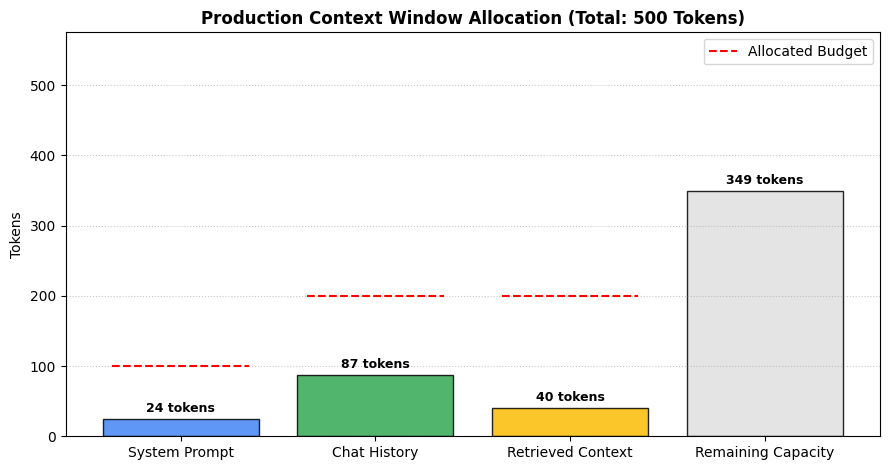

In [12]:
# YOUR CODE HERE
import logging
from datetime import datetime
import matplotlib.pyplot as plt

class ProductionSystem:
    """
    Production-ready Context Window & Memory Manager for AI Digital Twins.

    Architecture:
    1. Multi-Zone Token Allocation (System Instructions, Chat History, RAG Knowledge)
    2. FIFO History Pruning with Truncation Guard (Preserves latest user turn)
    3. Sliding Window & Token Budget Enforcement
    4. Diagnostic Logging and Structured Analytics
    5. Visual Context Inspection
    """
    def __init__(self, max_tokens: int = 1024, zone_splits: Dict[str, float] = None):
        if not isinstance(max_tokens, int) or max_tokens <= 0:
            raise ValueError(f"'max_tokens' must be a positive integer. Got: {max_tokens}")

        default_splits = {
            'system_prompt': 0.20,       # 20% reserved for instructions
            'conversation_history': 0.40, # 40% reserved for chat memory
            'retrieved_context': 0.40    # 40% reserved for retrieved RAG chunks
        }
        self.splits = zone_splits or default_splits

        # Verify split ratios sum to 1.0
        total_split = sum(self.splits.values())
        if not (0.99 <= total_split <= 1.01):
            raise ValueError(f"Zone allocations must sum to 1.0, got: {total_split:.2f}")

        self.max_tokens = max_tokens
        self.zone_budgets = {k: int(max_tokens * v) for k, v in self.splits.items()}
        self.logs = []

    def _log(self, message: str, level: str = "INFO"):
        """Records diagnostic logs with timestamps."""
        timestamp = datetime.now().strftime("%H:%M:%S.%f")[:-3]
        log_entry = f"[{timestamp}] [{level}] {message}"
        self.logs.append(log_entry)

    def estimate_tokens(self, text: Any) -> int:
        """Estimates token length using standard ~4 chars or 0.75 words per token heuristic."""
        if text is None:
            return 0
        if isinstance(text, list):
            flat = " ".join([str(item).strip() for item in text if item])
        elif isinstance(text, dict):
            flat = " ".join([f"{k}: {v}" for k, v in text.items()])
        elif isinstance(text, str):
            flat = text.strip()
        else:
            raise TypeError(f"Invalid content type: {type(text).__name__}. Expected str, list, or dict.")

        if not flat:
            return 0
        char_est = len(flat) / 4.0
        word_est = len(flat.split()) * 1.33
        return max(1, int(round((char_est + word_est) / 2)))

    def prune_history_fifo(self, messages: List[str], budget: int) -> Tuple[List[str], int]:
        """
        FIFO truncation with a safety guard: retains the most recent message while pruning oldest turns.
        """
        if not isinstance(messages, list):
            raise TypeError(f"messages must be a list of strings, got {type(messages).__name__}")

        active_messages = list(messages)
        while active_messages and self.estimate_tokens(active_messages) > budget:
            # Safety guard: keep at least the last message
            if len(active_messages) <= 1:
                self._log("Safety guard reached: retaining the final user query.", level="WARN")
                break
            removed = active_messages.pop(0)
            self._log(f"FIFO Pruned oldest message: '{removed[:40]}...'", level="DEBUG")

        used_tokens = self.estimate_tokens(active_messages)
        return active_messages, used_tokens

    def process(self, input_data: Dict[str, Any]) -> Dict[str, Any]:
        """
        Processes multi-zone inputs, enforces token budgets, prunes overflows, and builds prompt context.
        """
        if not isinstance(input_data, dict):
            raise TypeError(f"Expected dict for input_data, got {type(input_data).__name__}")

        self._log("Initiating context window processing.")
        system_text = input_data.get('system_prompt', '')
        history_list = input_data.get('conversation_history', [])
        context_chunks = input_data.get('retrieved_context', [])

        # 1. System Prompt Assessment
        sys_tokens = self.estimate_tokens(system_text)
        if sys_tokens > self.zone_budgets['system_prompt']:
            self._log(f"System prompt ({sys_tokens} tokens) exceeds budget ({self.zone_budgets['system_prompt']}).", level="WARN")

        # 2. Conversation History Management (FIFO Pruning)
        pruned_history, hist_tokens = self.prune_history_fifo(
            history_list, self.zone_budgets['conversation_history']
        )

        # 3. Retrieved RAG Context Management
        rag_tokens = self.estimate_tokens(context_chunks)
        selected_rag = list(context_chunks)
        while selected_rag and rag_tokens > self.zone_budgets['retrieved_context']:
            dropped = selected_rag.pop()
            self._log(f"RAG context exceeded budget: dropped lowest-ranked chunk.", level="DEBUG")
            rag_tokens = self.estimate_tokens(selected_rag)

        total_used = sys_tokens + hist_tokens + rag_tokens
        remaining = max(0, self.max_tokens - total_used)

        report = {
            'max_tokens': self.max_tokens,
            'total_used': total_used,
            'remaining_tokens': remaining,
            'usage_percent': round((total_used / self.max_tokens) * 100, 2),
            'system_tokens': sys_tokens,
            'history_tokens': hist_tokens,
            'retrieved_tokens': rag_tokens,
            'pruned_messages_count': len(history_list) - len(pruned_history),
            'active_history': pruned_history,
            'active_rag_chunks': selected_rag
        }
        self._log(f"Completed context compilation. Total tokens used: {total_used}/{self.max_tokens} ({report['usage_percent']}%)")
        return report

    def visualize_results(self, report: Dict[str, Any]):
        """Creates a visualization of token allocation vs usage."""
        categories = ['System Prompt', 'Chat History', 'Retrieved Context', 'Remaining Capacity']
        used_values = [
            report['system_tokens'],
            report['history_tokens'],
            report['retrieved_tokens'],
            report['remaining_tokens']
        ]
        budgets = [
            self.zone_budgets['system_prompt'],
            self.zone_budgets['conversation_history'],
            self.zone_budgets['retrieved_context'],
            self.max_tokens
        ]

        fig, ax = plt.subplots(figsize=(9, 4.8))
        colors = ['#4285F4', '#34A853', '#FBBC05', '#E0E0E0']

        bars = ax.bar(categories, used_values, color=colors, edgecolor='black', alpha=0.85)

        # Add budget markers for each active zone
        for idx in range(3):
            ax.hlines(budgets[idx], xmin=idx-0.35, xmax=idx+0.35, colors='red', linestyles='--', label='Allocated Budget' if idx == 0 else "")

        for bar in bars:
            height = bar.get_height()
            ax.annotate(f'{height} tokens',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points",
                        ha='center', va='bottom', fontsize=9, fontweight='bold')

        ax.set_title(f"Production Context Window Allocation (Total: {report['max_tokens']} Tokens)", fontsize=12, fontweight='bold')
        ax.set_ylabel('Tokens')
        ax.set_ylim(0, max(budgets) * 1.15)
        ax.legend(loc='upper right')
        ax.grid(axis='y', linestyle=':', alpha=0.7)
        plt.tight_layout()
        plt.show()


# ==============================================================================
# Execution & Verification
# ==============================================================================

# Initialize production system with 500 token budget
production_system = ProductionSystem(max_tokens=500)

sample_digital_twin_payload = {
    'system_prompt': "You are an AI Digital Twin representing Victor. Strictly ground your answers in retrieved personal notes.",
    'conversation_history': [
        "User: Did I attend the tech event last year?",
        "Twin: Yes, you attended networking sessions at KICC.",
        "User: Where is my next marathon training run scheduled?",
        "Twin: Your next scheduled training run is 10km around Parklands on Saturday morning.",
        "User: What was my best 5km time?",
        "Twin: Your record 5km was 25min.",
        "User: Can you check my calendar for upcoming symposium dates?"
    ],
    'retrieved_context': [
        "Chunk 1: Nairobi AI Symposium starts 2026-05-10 at Hall A. Contact lead@africatech.org for badge access.",
        "Chunk 2: Fitness log: Long run preparations scheduled for weekend mornings."
    ]
}

# Run pipeline
report = production_system.process(sample_digital_twin_payload)

print("=" * 65)
print("📊 PRODUCTION CONTEXT REPORT:")
print("=" * 65)
print(json.dumps(report, indent=2))

print("\n" + "=" * 65)
print("📝 DIAGNOSTIC LOGS:")
print("=" * 65)
for entry in production_system.logs:
    print(entry)

# Display chart
production_system.visualize_results(report)

---
## Summary & Key Takeaways

### What We Learned:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Understanding token limits and context windows System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

📊 DIGITAL TWIN CONTEXT COMPILATION REPORT
{
  "max_tokens": 500,
  "total_used": 241,
  "remaining_tokens": 259,
  "usage_ratio": 0.482,
  "zone_breakdown": {
    "system_prompt": {
      "budget": 100,
      "used": 57
    },
    "conversation_history": {
      "budget": 200,
      "used": 122
    },
    "retrieved_context": {
      "budget": 200,
      "used": 62
    }
  },
  "pruned_messages": 0,
  "retained_chunks": 3,
  "compiled_prompt_preview": "=== SYSTEM INSTRUCTIONS ===\nYou are Victor Nditika's AI Digital Twin. Respond with authentic warmth, clarity, and precision. Ground your answers strictly in Victor's verified history, Nairobi tech events, and personal schedule. Cite private source do..."
}

📝 DIAGNOSTIC LOGS
[16:00:03.553] [INFO] Beginning context compilation pipeline.
[16:00:03.553] [INFO] Context compiled successfully: 241/500 tokens (48.2% capacity).


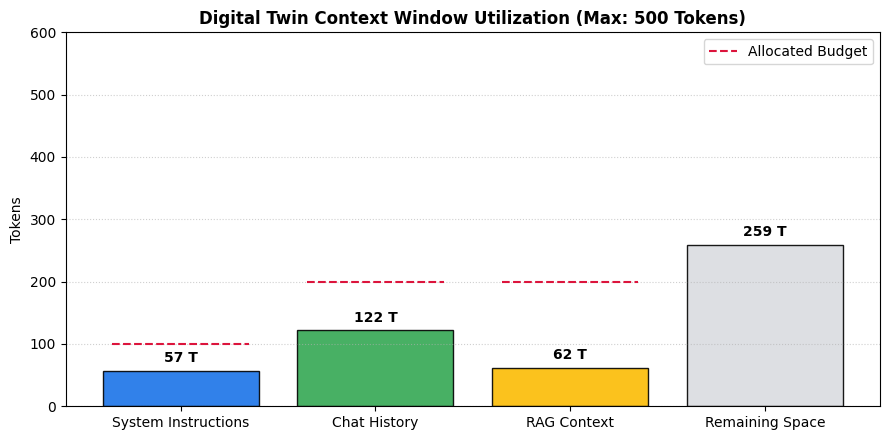

test_empty_string (__main__.TestContextWindowSystem.test_empty_string) ... ok
test_parameter_validation (__main__.TestContextWindowSystem.test_parameter_validation) ... ok
test_truncation_guard (__main__.TestContextWindowSystem.test_truncation_guard) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.009s

OK



🧪 RUNNING UNIT TESTS


<unittest.runner.TextTestResult run=3 errors=0 failures=0>

In [13]:
# ==============================================================================
# 🏆 CHALLENGE PROJECT: COMPLETE CONTEXT WINDOW MANAGEMENT SYSTEM
# ==============================================================================
import re
import json
import logging
import unittest
from datetime import datetime
from typing import List, Dict, Any, Tuple
import matplotlib.pyplot as plt


class DigitalTwinContextManager:
    """
    Production-grade Context Window & Working Memory Manager for Victor's Digital Twin.

    Features:
    1. Three-Zone Window Anatomy (System Prompt, Conversation History, RAG Knowledge)
    2. Dynamic token budget allocation & heuristic estimation
    3. FIFO History Pruning with Truncation Guard (Preserves user query)
    4. Sliding-window chunk compression for long document retrieval
    5. Real-time telemetry, structured diagnostics, and Matplotlib visual inspection
    """

    def __init__(
        self,
        max_tokens: int = 1024,
        zone_ratios: Dict[str, float] = None,
        char_per_token: float = 4.0,
        words_per_token: float = 0.75
    ):
        if not isinstance(max_tokens, int) or max_tokens <= 0:
            raise ValueError(f"max_tokens must be a positive integer. Got: {max_tokens}")

        self.max_tokens = max_tokens
        self.char_per_token = char_per_token
        self.words_per_token = words_per_token

        # Standard 3-Zone Window Anatomy
        default_ratios = {
            'system_prompt': 0.20,        # 20% reserved for instructions & identity
            'conversation_history': 0.40, # 40% reserved for chat memory
            'retrieved_context': 0.40     # 40% reserved for RAG facts
        }
        self.zone_ratios = zone_ratios or default_ratios
        total_ratio = sum(self.zone_ratios.values())
        if not (0.99 <= total_ratio <= 1.01):
            raise ValueError(f"Zone ratios must sum to 1.0, got: {total_ratio:.2f}")

        self.zone_budgets = {
            zone: int(self.max_tokens * ratio) for zone, ratio in self.zone_ratios.items()
        }
        self.logs: List[str] = []

    def _log(self, message: str, level: str = "INFO"):
        """Captures structured diagnostic telemetry."""
        timestamp = datetime.now().strftime("%H:%M:%S.%f")[:-3]
        self.logs.append(f"[{timestamp}] [{level}] {message}")

    def estimate_tokens(self, content: Any) -> int:
        """
        Calculates token length using a conservative dual heuristic:
        ~4 characters per token and ~0.75 words per token.
        """
        if content is None:
            return 0
        if isinstance(content, list):
            flat_text = " ".join([str(item).strip() for item in content if item])
        elif isinstance(content, dict):
            flat_text = " ".join([f"{k}: {v}" for k, v in content.items()])
        elif isinstance(content, str):
            flat_text = content.strip()
        else:
            raise TypeError(f"Unsupported content type: {type(content).__name__}")

        if not flat_text:
            return 0

        # Heuristic math
        char_count = len(flat_text)
        word_count = len(flat_text.split())
        est_by_chars = char_count / self.char_per_token
        est_by_words = word_count / self.words_per_token

        return max(1, int(round((est_by_chars + est_by_words) / 2)))

    def prune_history_fifo(self, history: List[str], budget: int) -> Tuple[List[str], int]:
        """
        Applies FIFO truncation with a safety guard to ensure the active user query is never pruned.
        """
        if not isinstance(history, list):
            raise TypeError(f"History must be a list of message strings. Got: {type(history).__name__}")

        active_history = list(history)
        while active_history and self.estimate_tokens(active_history) > budget:
            # Truncation Guard: Keep at least the latest user prompt
            if len(active_history) <= 1:
                self._log("Truncation Guard engaged: Keeping final user message.", level="WARN")
                break
            removed = active_history.pop(0)
            self._log(f"FIFO Pruned oldest turn: '{removed[:45]}...'", level="DEBUG")

        used = self.estimate_tokens(active_history)
        return active_history, used

    def compress_retrieved_context(self, chunks: List[str], budget: int) -> Tuple[List[str], int]:
        """
        Sliding-window context compression: retains top-ranked RAG chunks fitting within the budget.
        """
        if not isinstance(chunks, list):
            raise TypeError(f"Chunks must be a list of strings. Got: {type(chunks).__name__}")

        retained = []
        accumulated_tokens = 0

        for idx, chunk in enumerate(chunks):
            chunk_tokens = self.estimate_tokens(chunk)
            if accumulated_tokens + chunk_tokens <= budget:
                retained.append(chunk)
                accumulated_tokens += chunk_tokens
            else:
                self._log(f"Dropped RAG chunk {idx + 1} to respect retrieval budget ({accumulated_tokens}/{budget} tokens).", level="DEBUG")

        return retained, accumulated_tokens

    def process(self, payload: Dict[str, Any]) -> Dict[str, Any]:
        """
        Executes end-to-end context window compilation across all three zones.
        """
        if not isinstance(payload, dict):
            raise TypeError(f"Expected dict for payload, received: {type(payload).__name__}")

        self._log("Beginning context compilation pipeline.")

        # 1. System Prompt
        system_text = payload.get('system_prompt', '')
        sys_tokens = self.estimate_tokens(system_text)
        if sys_tokens > self.zone_budgets['system_prompt']:
            self._log(f"System prompt ({sys_tokens} tokens) exceeds allocated budget ({self.zone_budgets['system_prompt']}).", level="WARN")

        # 2. Conversation History (FIFO + Guard)
        raw_history = payload.get('conversation_history', [])
        active_history, hist_tokens = self.prune_history_fifo(
            raw_history, self.zone_budgets['conversation_history']
        )

        # 3. Retrieved RAG Context (Sliding Window Budget)
        raw_chunks = payload.get('retrieved_context', [])
        active_chunks, rag_tokens = self.compress_retrieved_context(
            raw_chunks, self.zone_budgets['retrieved_context']
        )

        total_used = sys_tokens + hist_tokens + rag_tokens
        remaining = max(0, self.max_tokens - total_used)

        # Assemble compiled prompt stack ready for model generation
        compiled_prompt = (
            f"=== SYSTEM INSTRUCTIONS ===\n{system_text}\n\n"
            f"=== GROUNDED RETRIEVED CONTEXT ===\n" + "\n".join([f"[{i+1}] {c}" for i, c in enumerate(active_chunks)]) + "\n\n"
            f"=== CONVERSATION LOG ===\n" + "\n".join(active_history)
        )

        report = {
            'max_tokens': self.max_tokens,
            'total_used': total_used,
            'remaining_tokens': remaining,
            'usage_ratio': round(total_used / self.max_tokens, 4),
            'zone_breakdown': {
                'system_prompt': {'budget': self.zone_budgets['system_prompt'], 'used': sys_tokens},
                'conversation_history': {'budget': self.zone_budgets['conversation_history'], 'used': hist_tokens},
                'retrieved_context': {'budget': self.zone_budgets['retrieved_context'], 'used': rag_tokens}
            },
            'pruned_messages': len(raw_history) - len(active_history),
            'retained_chunks': len(active_chunks),
            'compiled_prompt_preview': compiled_prompt[:250] + "..."
        }
        self._log(f"Context compiled successfully: {total_used}/{self.max_tokens} tokens ({report['usage_ratio']*100:.1f}% capacity).")
        return report

    def visualize(self, report: Dict[str, Any]):
        """Visualizes token allocation and consumption against window limits."""
        zones = ['System Instructions', 'Chat History', 'RAG Context', 'Remaining Space']
        used = [
            report['zone_breakdown']['system_prompt']['used'],
            report['zone_breakdown']['conversation_history']['used'],
            report['zone_breakdown']['retrieved_context']['used'],
            report['remaining_tokens']
        ]
        budgets = [
            self.zone_budgets['system_prompt'],
            self.zone_budgets['conversation_history'],
            self.zone_budgets['retrieved_context'],
            self.max_tokens
        ]

        fig, ax = plt.subplots(figsize=(9, 4.5))
        colors = ['#1a73e8', '#34a853', '#fbbc04', '#dadce0']
        bars = ax.bar(zones, used, color=colors, edgecolor='black', alpha=0.9)

        for i in range(3):
            ax.hlines(budgets[i], xmin=i - 0.35, xmax=i + 0.35, colors='crimson', linestyles='--', label='Allocated Budget' if i == 0 else "")

        for bar in bars:
            h = bar.get_height()
            ax.annotate(f"{h} T", xy=(bar.get_x() + bar.get_width() / 2, h),
                        xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

        ax.set_title(f"Digital Twin Context Window Utilization (Max: {self.max_tokens} Tokens)", fontsize=12, fontweight='bold')
        ax.set_ylabel("Tokens")
        ax.set_ylim(0, max(budgets) * 1.2)
        ax.legend(loc='upper right')
        ax.grid(axis='y', linestyle=':', alpha=0.6)
        plt.tight_layout()
        plt.show()


# ==============================================================================
# PIPELINE EXECUTION USING VICTOR'S PERSONAL DIGITAL TWIN CONTEXT
# ==============================================================================

# Initialize context manager with 500 token budget
twin_context_manager = DigitalTwinContextManager(max_tokens=500)

# Persona & memory payload tailored to your profile
victor_payload = {
    'system_prompt': (
        "You are Victor Nditika's AI Digital Twin. Respond with authentic warmth, clarity, and precision. "
        "Ground your answers strictly in Victor's verified history, Nairobi tech events, and personal schedule. "
        "Cite private source documents and avoid ungrounded hallucinations."
    ),
    'conversation_history': [
        "User: Did I confirm my reservation at The Talisman for July 12th?",
        "Twin: Yes, your group reservation for 35 guests at The Talisman was confirmed.",
        "User: Which cloud provider hosts our primary server infrastructure?",
        "Twin: Your VPS and server infrastructure are hosted on Contabo, with satellite backup via Starlink.",
        "User: Did I finish the ATF AI Challenge curriculum?",
        "Twin: Yes, you successfully completed both the ALX AI program and the ATF AI Challenge.",
        "User: What events am I scheduled to attend at KICC or Sarit Centre?"
    ],
    'retrieved_context': [
        "Doc 1: AI Everything Kenya x GITEX Kenya event scheduled at Sarit Centre and KICC in Nairobi.",
        "Doc 2: Parklands Sports Club membership schedule: Weekend training session and dining reservation.",
        "Doc 3: Kentex Cargo shipping receipt: USA to Nairobi package clearance verified."
    ]
}

# Run execution
report = twin_context_manager.process(victor_payload)

print("=" * 65)
print("📊 DIGITAL TWIN CONTEXT COMPILATION REPORT")
print("=" * 65)
print(json.dumps(report, indent=2))

print("\n" + "=" * 65)
print("📝 DIAGNOSTIC LOGS")
print("=" * 65)
for log in twin_context_manager.logs:
    print(log)

# Render visualization
twin_context_manager.visualize(report)


# ==============================================================================
# BONUS CHALLENGE: AUTOMATED UNIT TESTS
# ==============================================================================

class TestContextWindowSystem(unittest.TestCase):
    def setUp(self):
        self.mgr = DigitalTwinContextManager(max_tokens=200)

    def test_parameter_validation(self):
        with self.assertRaises(ValueError):
            DigitalTwinContextManager(max_tokens=-50)

    def test_truncation_guard(self):
        oversized_history = ["Long turn message " * 15 for _ in range(5)]
        pruned, tokens = self.mgr.prune_history_fifo(oversized_history, budget=30)
        self.assertEqual(len(pruned), 1, "Truncation guard must retain at least the latest user prompt.")

    def test_empty_string(self):
        self.assertEqual(self.mgr.estimate_tokens("   "), 0)

suite = unittest.TestLoader().loadTestsFromTestCase(TestContextWindowSystem)
print("\n" + "=" * 65)
print("🧪 RUNNING UNIT TESTS")
print("=" * 65)
unittest.TextTestRunner(verbosity=2).run(suite)